# Forward planning for the student: novelty and relevance (11/21/26)

The fitted student plays by intuition alone: on every board it samples a move from its policy head (MODEL.md). AND-OR's
backward reasoning is only its teacher in pretraining. The question here is whether a **heuristically guided forward
planner** - short rollouts, judged by how much new and goal-relevant ground they cover - is a good candidate for what
people add as they gain expertise, and where expertise would enter it.

Two ingredients:
- **Novelty** (Lipovetzky & Geffner's width-based planning): a *feature* is one car in one place on its lane; a rollout
  earns credit for features no board of the attempt has had yet.
- **Relevance**: the network's dest head scores every feature on the current board by how soon a solution from here
  puts that car there (target 0.8^(k-1) at k moves into the route, 0 if never); r(f) = sigmoid(dest). It is "how
  likely this new position is to be on the way to the goal".

This notebook reads tables written by `experiments/dest_quality.py` and `experiments/forward.py` (models/summary);
sections 1.3 and 1.4 compute their tables here.

In [1]:
import sys
sys.path.insert(0, "..")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rushhour import paths

SUMMARY = os.path.join(paths.MODELS, "summary")
INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
TEACHERS = {"no_teacher": ("no teacher", "#8a8a85"), "bayes4_0.45": ("bayes4", "#2a78d6"),
            "random_0.3": ("random 30%", "#e6a00d"), "random_1.0": ("random 100%", "#e6550d")}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)

## 1. Is the relevance map any good, and does it sharpen with experience?

Truth comes from breadth-first search: for every board, the optimal-route DAG, and for every feature the fewest moves
k at which some optimal route first puts that car there (none if no optimal route does). Boards: the 100 held-out
puzzles of the AND-OR apprentice (1-30 moves), each start plus 2 boards 3 random moves off it and 2 boards 8 random
moves off it (500 boards). About 35% of a board's ~40 features lie on some optimal route.

Measures (per board, then averaged; AUC 0.5 = chance):
- **on-route AUC**: features on some optimal route vs features on none;
- **next-move AUC**: features an optimal next move reaches (k = 1) vs the rest;
- **far AUC**: features first reached 3+ moves on vs off-route ones - the long-range part rollouts would need;
- **policy optimal**: share of boards where the policy head's top move is optimal (the proposals, for comparison).

### 1.1 Across the apprentice's pretraining

In [2]:
dq = pd.read_csv(os.path.join(SUMMARY, "dest_quality.csv"))
show = dq[dq.boards == "all"].copy()
order = ["round0_epoch00", "round1_epoch02", "round1_epoch11", "round2_epoch03", "round3_epoch03", "previous start"]
names = {"round0_epoch00": "untrained", "round1_epoch02": "start (round 1, epoch 2)", "round1_epoch11": "round 1, epoch 11",
         "round2_epoch03": "round 2, epoch 3", "round3_epoch03": "round 3, epoch 3", "previous start": "previous start"}
table = (show.set_index("network").loc[[n for n in order if n in set(show.network)]]
         [["on-route AUC", "next-move AUC", "far AUC", "precision", "base rate", "policy optimal"]]
         .rename(index=names).round(3))
table

,on-route AUC,next-move AUC,far AUC,precision,base rate,policy optimal
network,,,,,,
untrained,0.511,0.549,0.488,0.357,0.345,0.404
"start (round 1, epoch 2)",0.737,0.876,0.673,0.565,0.345,0.746
"round 1, epoch 11",0.742,0.884,0.682,0.574,0.345,0.638
"round 2, epoch 3",0.800,0.885,0.758,0.639,0.345,0.788
"round 3, epoch 3",0.829,0.870,0.801,0.669,0.345,0.774
previous start,0.747,0.915,0.676,0.567,0.345,0.718


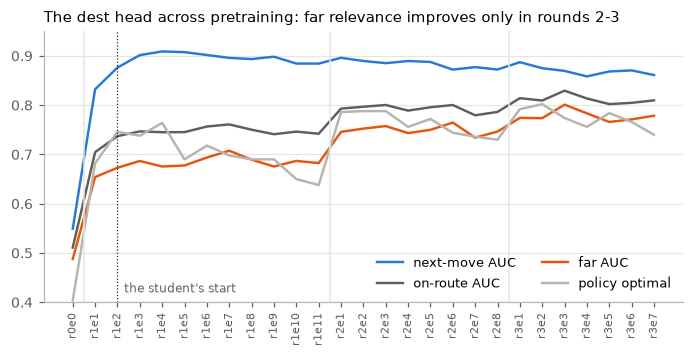

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ap = dq[(dq.boards == "all") & dq["round"].notna()].copy()
ap["x"] = np.arange(len(ap))
for col, color in [("next-move AUC", "#2a78d6"), ("on-route AUC", "#5f5e5a"), ("far AUC", "#e6550d"),
                   ("policy optimal", "#b5b4ad")]:
    ax.plot(ap.x, ap[col], color=color, lw=1.6, label=col)
for r in sorted(ap["round"].unique())[1:]:
    ax.axvline(ap[ap["round"] == r].x.min() - 0.5, color=GRID, lw=1)
start = ap[ap.network == "round1_epoch02"].x.iloc[0]
ax.axvline(start, color=INK, lw=0.8, ls=":")
ax.text(start + 0.3, 0.42, "the student's start", color=MUTED, fontsize=8)
ax.set_xticks(ap.x, [f"r{int(r)}e{int(e)}" for r, e in zip(ap["round"], ap.epoch)], rotation=90, fontsize=7)
ax.set_ylim(0.4, 0.95)
ax.set_title("The dest head across pretraining: far relevance improves only in rounds 2-3")
ax.legend(loc="lower right", ncol=2)
tidy(ax)
plt.show()

Next-move relevance is learned within about three epochs and then stops. Far relevance stays at about 0.68 through
round 1 (more epochs of copying plain AND-OR do not help) and rises in rounds 2 and 3, where the expert is AND-OR
ordered by the network and its routes are shorter: the long-range map comes from better routes to learn from. Off-route
boards (3 or 8 random moves off the start) give nearly the same numbers:

In [4]:
(dq[dq.network.isin(["round1_epoch02", "round3_epoch03"])].pivot(index="boards", columns="network",
                                                                  values=["on-route AUC", "far AUC"]).round(3))

on-route AUC                       far AUC               
network        round1_epoch02 round3_epoch03 round1_epoch02 round3_epoch03
boards                                                                    
3 random moves          0.733          0.827          0.667          0.798
8 random moves          0.733          0.828          0.670          0.803
all                     0.737          0.829          0.673          0.801
start                   0.754          0.838          0.692          0.805

### 1.2 Within a session

The same measures for the session students (run `aostart_free_m10_s2_agency1`: seed 2, ΔA 1, 8 students per
teacher), at every saved snapshot.

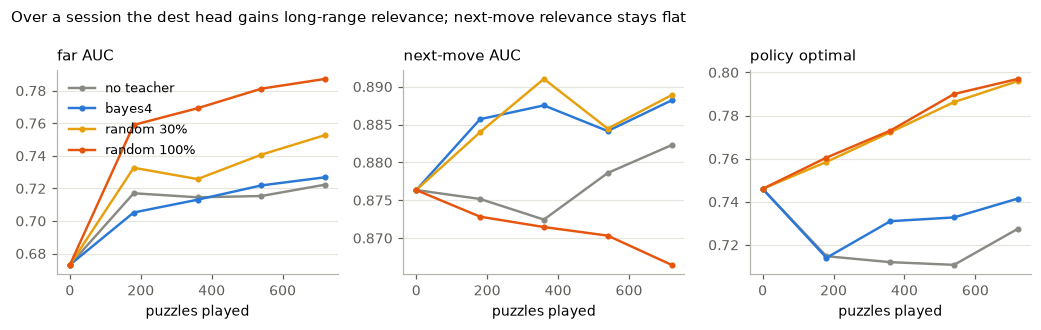

In [5]:
ds = pd.read_csv(os.path.join(SUMMARY, "dest_quality_session.csv"))
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3), sharex=True)
for ax, col in zip(axes, ["far AUC", "next-move AUC", "policy optimal"]):
    for teacher, (label, color) in TEACHERS.items():
        d = ds[ds.teacher == teacher]
        ax.plot(d.puzzle, d[col], color=color, lw=1.6, marker="o", ms=3, label=label)
    ax.set_title(col)
    ax.set_xlabel("puzzles played")
    tidy(ax)
axes[0].legend()
fig.suptitle("Over a session the dest head gains long-range relevance; next-move relevance stays flat", x=0.01,
             ha="left", fontsize=10)
plt.tight_layout()
plt.show()

With no teacher, far AUC rises 0.67 → 0.72 while next-move AUC and the policy's top move stay flat; teachers that
show more moves sharpen it further (random 100%: 0.79). One seed, 8 students per teacher; no standard errors.

### 1.3 What the values look like

AUC only measures ranking. In a score that sums relevance, the scale matters too. Features of the 100 start boards,
grouped by when the nearest optimal route first needs them:

In [6]:
sys.path.insert(0, os.path.join("..", "experiments"))
import torch
import dest_quality as dq_mod
from rushhour.student import PolicyAgent
from rushhour.student.labels import _destinations, _move_index

starts = [it for it in dq_mod.boards() if it["kind"] == "start"]
rows = []
for name, path in [("start", paths.START),
                   ("round 3", os.path.join(paths.APPRENTICE, "gamma0.07_free", "round3_epoch03.pt"))]:
    agent = PolicyAgent.load(path)
    for it in starts:
        b = it["board"]
        sd, dest = dict(b), agent._evaluate(b)[1]
        for car, d, s, moved in _destinations(b, (6, 6), agent.max_slide):
            k = it["first"].get((car, moved))
            r = torch.sigmoid(dest[_move_index(sd, car, d, s, 6, agent.max_slide)]).item()
            rows.append({"network": name, "k": k or 0, "r": r})
feat = pd.DataFrame(rows)
feat["needed"] = pd.cut(feat.k, [-1, 0, 1, 2, 5, 99], labels=["never (off route)", "next move (k=1)", "k=2", "k=3-5",
                                                               "k>5"])
calib = feat.groupby(["needed", "network"], observed=True).r.mean().unstack().round(3)
calib.insert(0, "target", [0, 1, 0.8, None, None])
calib.insert(0, "share", (feat[feat.network == "start"].needed.value_counts(normalize=True).reindex(calib.index)
                          .round(2)))
calib

network,share,target,round 3,start
needed,,,,
never (off route),0.60,0.0,0.042,0.069
next move (k=1),0.09,1.0,0.353,0.274
k=2,0.05,0.8,0.285,0.195
k=3-5,0.10,NaN,0.198,0.155
k>5,0.17,NaN,0.145,0.109


The ordering is right but the scale is compressed: even features needed on the next move score about 0.3, because
the head was trained on one route per board while many exist. Experience mostly widens the gap between needed and
unneeded features (next move vs off route: about 4× at the start, 8× at round 3). In a sum, 60% of features are off
route at 0.04-0.07 each, so a rollout that pushes five cars somewhere new and irrelevant scores about as much as one
that does the thing needed next.

### 1.4 The value head

The third head predicts a board's moves to go (in tens; trained on the moves left on the solved routes it learns
from). Nothing in the session reads it. On the 100 start boards: how well it ranks true distances, its typical
error, and how often the successor it rates closest to the goal is an optimal move (the policy head's top move is
optimal on 85-87% of these start boards):

In [7]:
from scipy.stats import spearmanr
from rushhour import board

SESSION = os.path.join(paths.MODELS, "sessions", "aostart_free_m10_s2_agency1")
VALUE_NETS = {"start": paths.START, "round 3": os.path.join(paths.APPRENTICE, "gamma0.07_free", "round3_epoch03.pt"),
              "student, no teacher (s0, 720)": os.path.join(SESSION, "no_teacher", "student00_puzzle720.pt"),
              "student, random 100% (s0, 720)": os.path.join(SESSION, "random_1.0", "student00_puzzle720.pt")}
succ = []
for it in starts:
    b = it["board"]
    dist = board.multi_bfs(b)
    nxt = [s for _, s in board.neighbors(b, board.car_orientations(b))]
    succ.append((nxt, [dist[s] == it["distance"] - 1 for s in nxt]))
rows = {}
for name, path in VALUE_NETS.items():
    agent = PolicyAgent.load(path)
    agent.net.eval()

    def moves_to_go(states):
        with torch.no_grad():
            return 10 * agent.net.heads(torch.stack([agent.encoder.encode(s) for s in states]))[2].numpy()

    pred, true = moves_to_go([it["board"] for it in starts]), np.array([it["distance"] for it in starts])
    rows[name] = {"spearman with distance": spearmanr(pred, true).statistic,
                  "mean abs error (moves)": np.abs(pred - true).mean(),
                  "closest-rated successor optimal": np.mean([opt[int(np.argmin(moves_to_go(nxt)))]
                                                              for nxt, opt in succ])}
pd.DataFrame(rows).T.round(3)

,spearman with distance,mean abs error (moves),closest-rated successor optimal
start,0.633,12.803,0.78
round 3,0.769,4.392,0.78
"student, no teacher (s0, 720)",0.661,4.480,0.85
"student, random 100% (s0, 720)",0.667,3.821,0.81


It ranks boards moderately (spearman 0.63-0.77) and, used greedily, picks an optimal move on 78-85% of start
boards, about as often as the policy (85-87%). Over all 500 boards, including those off the route, it does worse:
57-68%, against the policy's 75% (a check run outside this notebook). The start's absolute error is large: AND-OR's routes are long, so "moves left" is inflated;
the session's own shorter routes pull it down.

## 2. The forward planner

`experiments/forward.py`, `solve_forward`. Every turn, on board b:
1. **relevance**: the dest head on b gives r(f) for every feature;
2. **proposals**: K rollouts of up to D moves, each move sampled from the policy head at temperature 1 (never back
   to one of the last 10 boards of the attempt or to a board earlier in the rollout, if it can avoid it);
3. **evaluation**: a rollout that solves the puzzle wins (the shortest); otherwise its score is the sum of r(f) over
   the features it reaches that **no board of the attempt has had**, each counted once;
4. the first move of the best rollout is played (the first sampled, on a tie).

**How strict novelty is.** Two mechanisms, only one of which forbids anything:
- *Hard, over whole boards* (the session student's own rule): a move back to one of the last 10 boards of the
  attempt is removed from the options - for the move played and for every rollout step - and, inside a rollout,
  so is a move back to any of its earlier boards; if every move would, all are allowed again.
- *Soft, over features* (the planner's score): no feature is forbidden. A feature seen anywhere in the attempt is
  worth 0 from then on (no fading); a new one gets its full relevance. It only ranks the K rollouts: if none reaches
  anything new, they all score 0 and the first sampled one is played - a plain policy sample (the "ties" below).
  A pruning version, as in Iterated Width, would instead discard such rollouts.

K = 1 is the session student's intuition exactly. Test: 100 of the session's held-out puzzles (25 per bin of 9-11,
14-16, 19-21 and 24-26 moves), 2 runs each, cap max(50, 10 × optimal), no giving up. Score: moves/optimal with an
unsolved puzzle counted at its cap (lower is better). Networks: the start, round 3 of pretraining, and the 8 students
of the no-teacher and random-100% teachers after 720 puzzles (same session run as 1.2).

Conditions:
- **novelty only**: every r(f) = 1;
- **no attempt memory**: a feature counts as new if it isn't on b (the current board), so relevance acts as a pure
  lookahead evaluator;
- **uniform**: rollout moves drawn uniformly from the legal ones, so the network acts only through relevance (and
  "uniform, novelty only" uses no network at all);
- **K16 D8**: more and deeper rollouts;
- **value**: rollouts ranked by the value head's moves to go at their end board (fewest first), no novelty;
- **novelty then value**: novelty count first, the value head breaking ties (best-first width search ranks by
  novelty, then a goal heuristic).

In [8]:
fw = pd.concat([pd.read_csv(os.path.join(SUMMARY, "forward.csv")),
                pd.read_csv(os.path.join(SUMMARY, "forward_uniform.csv")),
                pd.read_csv(os.path.join(SUMMARY, "forward_value.csv"))])
fw["ratio"] = np.where(fw.solved, fw.moves, fw.cap) / fw.distance
fw["group"] = fw.network.str.replace(r" s\d$", "", regex=True)
GROUPS = {"start": "start", "round 3": "round 3", "no_teacher 720": "students, no teacher",
          "random_1.0 720": "students, random 100%"}
CONDS = ["intuition uniform", "intuition", "K8 D4 uniform value", "K8 D4 uniform novelty only", "K8 D4 uniform",
         "K8 D4 uniform novelty then value", "K8 D4 no attempt memory", "K8 D4 value", "K8 D4 novelty only", "K8 D4",
         "K8 D4 novelty then value", "K16 D8"]
LABELS = {"intuition uniform": "random walk", "intuition": "intuition (policy, no search)",
          "K8 D4 uniform novelty only": "uniform proposals, novelty only",
          "K8 D4 uniform": "uniform proposals, novelty × relevance",
          "K8 D4 no attempt memory": "policy proposals, relevance, no attempt memory",
          "K8 D4 novelty only": "policy proposals, novelty only", "K8 D4": "policy proposals, novelty × relevance",
          "K16 D8": "policy proposals, novelty × relevance, K16 D8",
          "K8 D4 uniform value": "uniform proposals, value", "K8 D4 value": "policy proposals, value",
          "K8 D4 uniform novelty then value": "uniform proposals, novelty then value",
          "K8 D4 novelty then value": "policy proposals, novelty then value"}


def cell(d):
    return f"{d.ratio.mean():.2f} ({d.solved.mean():.0%})"


table = pd.DataFrame({GROUPS[g]: {LABELS[c]: cell(fw[(fw.group == g) & (fw.condition == c)]) for c in CONDS}
                      for g in GROUPS})
table

,start,round 3,"students, no teacher","students, random 100%"
random walk,9.63 (10%),9.63 (10%),9.63 (10%),9.63 (10%)
"intuition (policy, no search)",5.98 (66%),3.66 (81%),5.08 (69%),4.36 (79%)
"uniform proposals, value",6.71 (60%),6.20 (61%),6.32 (62%),6.27 (65%)
"uniform proposals, novelty only",5.64 (72%),5.64 (72%),5.64 (72%),5.64 (72%)
"uniform proposals, novelty × relevance",5.75 (66%),5.64 (66%),5.52 (68%),5.45 (69%)
"uniform proposals, novelty then value",4.40 (84%),4.49 (80%),4.35 (84%),4.22 (87%)
"policy proposals, relevance, no attempt memory",5.91 (60%),3.51 (78%),5.03 (63%),4.28 (72%)
"policy proposals, value",4.48 (74%),3.49 (78%),4.11 (74%),3.61 (79%)
"policy proposals, novelty only",3.10 (89%),2.65 (88%),3.03 (86%),2.30 (95%)
"policy proposals, novelty × relevance",3.06 (90%),2.37 (90%),3.02 (87%),2.35 (94%)


Cells: moves/optimal (share solved). K8 D4 unless noted. "Random walk" and "uniform proposals, novelty only" use no
network, and every network ran them with the same seeds, so each is one sample of 200 attempts repeated
(about ±0.23).

In [9]:
CONTRASTS = [("does relevance help, given policy proposals?", "K8 D4", "K8 D4 novelty only"),
             ("does relevance help, given uniform proposals?", "K8 D4 uniform", "K8 D4 uniform novelty only"),
             ("do policy proposals help (novelty only)?", "K8 D4 novelty only", "K8 D4 uniform novelty only"),
             ("does search help the policy?", "K8 D4", "intuition"),
             ("does a bigger search help?", "K16 D8", "K8 D4"),
             ("value alone vs intuition (policy proposals)", "K8 D4 value", "intuition"),
             ("value alone vs novelty (policy proposals)", "K8 D4 value", "K8 D4 novelty only"),
             ("does value help novelty, breaking ties? (policy)", "K8 D4 novelty then value", "K8 D4 novelty only"),
             ("does value help novelty, breaking ties? (uniform)", "K8 D4 uniform novelty then value",
              "K8 D4 uniform novelty only")]


def contrast(g, a, b):
    """Mean difference a - b; ± is the SE over the 8 students, or for one network over its 200 attempts."""
    x, y = fw[(fw.group == g) & (fw.condition == a)], fw[(fw.group == g) & (fw.condition == b)]
    if x.network.nunique() > 1:
        d = x.groupby("network").ratio.mean() - y.groupby("network").ratio.mean()
        return f"{d.mean():+.2f} ± {d.std() / np.sqrt(len(d)):.2f}"
    se = np.sqrt(x.ratio.var() / len(x) + y.ratio.var() / len(y))
    return f"{x.ratio.mean() - y.ratio.mean():+.2f} ± {se:.2f}"


pd.DataFrame({GROUPS[g]: {q: contrast(g, a, b) for q, a, b in CONTRASTS} for g in GROUPS})

,start,round 3,"students, no teacher","students, random 100%"
"does relevance help, given policy proposals?",-0.05 ± 0.28,-0.28 ± 0.28,-0.01 ± 0.06,+0.04 ± 0.04
"does relevance help, given uniform proposals?",+0.11 ± 0.34,-0.00 ± 0.34,-0.12 ± 0.07,-0.19 ± 0.05
do policy proposals help (novelty only)?,-2.54 ± 0.31,-2.99 ± 0.31,-2.61 ± 0.05,-3.34 ± 0.03
does search help the policy?,-2.92 ± 0.32,-1.29 ± 0.31,-2.05 ± 0.07,-2.01 ± 0.04
does a bigger search help?,-0.58 ± 0.26,-0.18 ± 0.26,-0.57 ± 0.03,-0.58 ± 0.04
value alone vs intuition (policy proposals),-1.50 ± 0.36,-0.18 ± 0.36,-0.97 ± 0.05,-0.74 ± 0.04
value alone vs novelty (policy proposals),+1.38 ± 0.33,+0.83 ± 0.34,+1.08 ± 0.04,+1.31 ± 0.06
"does value help novelty, breaking ties? (policy)",-0.38 ± 0.28,-0.11 ± 0.29,-0.20 ± 0.04,-0.15 ± 0.04
"does value help novelty, breaking ties? (uniform)",-1.25 ± 0.31,-1.16 ± 0.31,-1.29 ± 0.04,-1.42 ± 0.04


Differences: row's condition minus its comparison (negative = fewer moves). ± is the standard error over the 8
students, or, for one network, over its 200 attempts. The students' ± understates the uncertainty: every student
played the same 100 puzzles with the same seeds, so the noise of that one sample (about ±0.25 per condition) is
shared and not counted. With uniform proposals, relevance may help slightly for the session students (−0.12,
−0.19), but not for round 3, whose map is the sharpest, so I read it as no reliable effect.

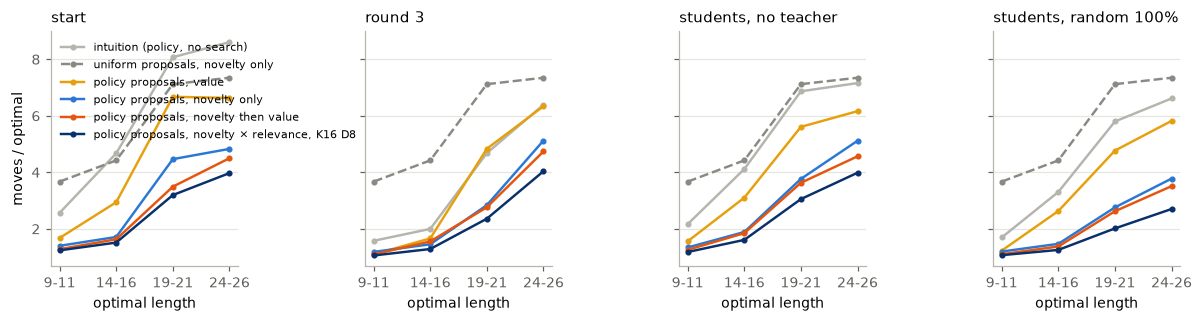

In [10]:
fw["bin"] = pd.cut(fw.distance, [8, 11, 16, 21, 26], labels=["9-11", "14-16", "19-21", "24-26"])
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
STYLE = {"intuition": ("#b5b4ad", "-"), "K8 D4 uniform novelty only": ("#8a8a85", "--"),
         "K8 D4 value": ("#e6a00d", "-"), "K8 D4 novelty only": ("#2a78d6", "-"),
         "K8 D4 novelty then value": ("#e6550d", "-"), "K16 D8": ("#08306b", "-")}
for ax, (g, title) in zip(axes, GROUPS.items()):
    for c, (color, ls) in STYLE.items():
        m = fw[(fw.group == g) & (fw.condition == c)].groupby("bin", observed=True).ratio.mean()
        ax.plot(m.index.astype(str), m.values, color=color, ls=ls, lw=1.6, marker="o", ms=3, label=LABELS[c])
    ax.set_title(title)
    ax.set_xlabel("optimal length")
    tidy(ax)
axes[0].set_ylabel("moves / optimal")
axes[0].legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

### One score: novelty and value combined, with fading memory

"Novelty, then value" ranks strictly: value only matters when novelty ties. A person would more plausibly fold
both into one judgment ("I haven't been here before, so I must be getting somewhere"):

  score = λ × novelty − moves to go (value head, at the rollout's end)

λ is how many moves of predicted progress one new feature is worth: λ = 0 is value alone, λ → ∞ is the strict
order. Novelty can also **fade**: a feature last on the attempt's boards `age` moves ago counts
1 − 0.5^(age / half-life) (1 if never seen, 0 on the current board), so a placement seen long ago detracts less
than one seen recently; an infinite half-life never forgets (all runs before this one).

`python experiments/forward.py sweep` → `forward_sweep.csv`: λ from 0.5 to 32 with policy and uniform proposals,
and half-lives of 5, 20 and 80 moves at λ 4 and 16 (policy proposals). The students here are 4 per teacher
(s0-s3), so the anchors below are recomputed on those 4.

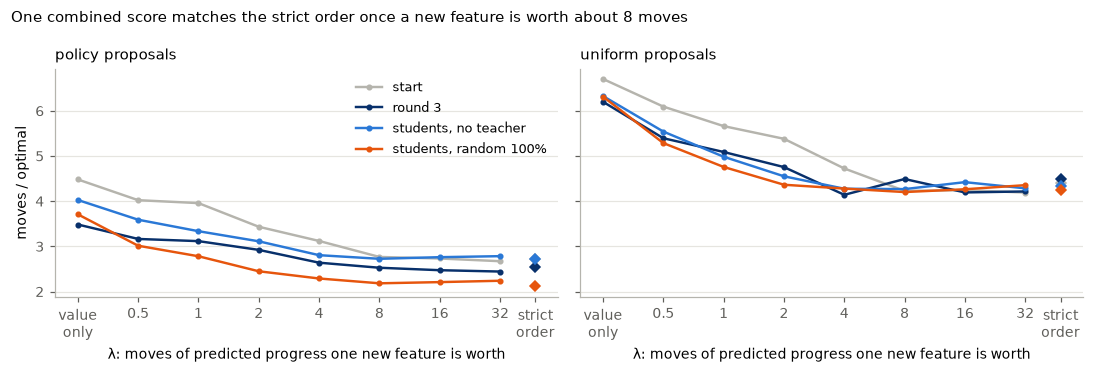

In [11]:
sw = pd.concat([fw, pd.read_csv(os.path.join(SUMMARY, "forward_sweep.csv"))])
sw = sw[~sw.network.str.contains(r" s[4-7]$")].copy()
sw["ratio"] = np.where(sw.solved, sw.moves, sw.cap) / sw.distance
sw["group"] = sw.network.str.replace(r" s\d$", "", regex=True)
LAMS = [0.5, 1, 2, 4, 8, 16, 32]
GROUP_COLORS = {"start": "#b5b4ad", "round 3": "#08306b", "no_teacher 720": "#2a78d6", "random_1.0 720": "#e6550d"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, prefix, title in [(axes[0], "K8 D4", "policy proposals"), (axes[1], "K8 D4 uniform", "uniform proposals")]:
    for g, color in GROUP_COLORS.items():
        d = sw[sw.group == g]
        m = [d[d.condition == f"{prefix} weighted lam{lam}"].ratio.mean() for lam in LAMS]
        v = d[d.condition == f"{prefix} value"].ratio.mean()
        strict = d[d.condition == f"{prefix} novelty then value"].ratio.mean()
        ax.plot([0.25] + LAMS, [v] + m, color=color, lw=1.6, marker="o", ms=3, label=GROUPS[g])
        ax.plot([48], [strict], color=color, marker="D", ms=5)
    ax.set_xscale("log", base=2)
    ax.set_xticks([0.25] + LAMS + [48], ["value\nonly"] + [str(x) for x in LAMS] + ["strict\norder"])
    ax.set_xlabel("λ: moves of predicted progress one new feature is worth")
    ax.set_title(title)
    tidy(ax)
axes[0].set_ylabel("moves / optimal")
axes[0].legend()
fig.suptitle("One combined score matches the strict order once a new feature is worth about 8 moves", x=0.01,
             ha="left", fontsize=10)
plt.tight_layout()
plt.show()

In [12]:
HALF = [("never", "K8 D4 weighted lam{}"), ("80", "K8 D4 weighted lam{} half-life80"),
        ("20", "K8 D4 weighted lam{} half-life20"), ("5", "K8 D4 weighted lam{} half-life5")]
fade = {}
for lam in (4, 16):
    for h, name in HALF:
        fade[(f"λ {lam}", f"half-life {h}")] = {GROUPS[g]: sw[(sw.group == g) & (sw.condition == name.format(lam))]
                                                .ratio.mean() for g in GROUP_COLORS}
pd.DataFrame(fade).T.round(2)

start  round 3  students, no teacher  \
λ 4  half-life never   3.12     2.64                  2.81   
     half-life 80      3.10     2.55                  2.83   
     half-life 20      2.99     2.66                  2.80   
     half-life 5       3.47     2.82                  3.10   
λ 16 half-life never   2.73     2.47                  2.76   
     half-life 80      2.52     2.47                  2.64   
     half-life 20      2.70     2.52                  2.73   
     half-life 5       2.88     2.56                  2.92   

                      students, random 100%  
λ 4  half-life never                   2.29  
     half-life 80                      2.27  
     half-life 20                      2.32  
     half-life 5                       2.53  
λ 16 half-life never                   2.21  
     half-life 80                      2.10  
     half-life 20                      2.14  
     half-life 5                       2.42

- **The combined score costs nothing once λ is about 8 or more.** At λ 8 it is level with the strict order
  (students +0.01 ± 0.02 and +0.07 ± 0.05; start and round 3 within ±0.3), and flat up to 32. Below 4 it loses
  (λ 2: +0.3 to +0.7): value then outweighs novelty and the planner circles as value alone does. So the human-like,
  compensatory version is viable, provided a new placement counts for a lot.
- **No clear sign that experience moves the best λ.** Every network is best somewhere in 8-32. The start loses most
  at low λ (+0.71 at λ 2, against +0.33 to +0.39), as if it should trust its value head least - but its value
  head's scale is inflated (1.4), so the same λ weighs novelty less for it; the units are not comparable across
  networks.
- **Fading memory is free over tens of moves, harmful over a few.** A half-life of 80 moves is at least as good as
  never forgetting (λ 16: students −0.12 ± 0.05 and −0.11 ± 0.07, start −0.22 ± 0.25); 20 is about level; 5 hurts
  (+0.08 to +0.20). Performance therefore does not pin the half-life down within a wide range - people's revisits
  must (when, after leaving a placement, they come back to it).

### What the planner shows

- **Search with attempt-level novelty roughly halves moves/optimal for every network**, and more search (K16 D8)
  helps further. The gain over intuition shrinks as the network gains experience (−2.9 at the start, −1.3 at round
  3), mostly because intuition itself gets better.
- **All of the network's contribution comes through proposals.** Policy instead of uniform proposals is worth 2.5-3.3;
  relevance is worth nothing measurable, whether the policy proposes (where it could be redundant) or uniform
  proposals leave it the network's only input. Without attempt memory, relevance as a lookahead evaluator is no
  better than intuition.
- **Blind novelty search is about as good as a novice's instinct** (5.64 vs the start's 5.98); the two together
  halve the moves.
- **A board evaluator helps where relevance could not: on novelty's ties.** The value head alone is a weak guide
  (better than intuition, 0.8-1.4 worse than novelty: greedy on a noisy value circles). Breaking novelty's ties
  with it - the turns where no rollout reaches anything new - helps a little with policy proposals (−0.1 to −0.4)
  and a lot with uniform ones (5.64 → 4.2-4.5). Summed relevance cannot act on those turns: every rollout scores 0.
  Its gain is about the same for every network, so the value head is not where experience shows up either.
- **Strict or compensatory makes no difference to performance** once a new feature is worth 8+ moves of
  value, and novelty can fade over tens of moves at no cost: both choices are for people's data to make.
- Novelty search is strong enough that adding it to the start student would break the fitted start: a novice's
  search budget would have to be near zero and grow with practice.

## 3. How this relates to the papers

- **van Opheusden et al. 2023** (four-in-a-row): best-first search over a feature-weighted value; expertise is mostly
  more search (depth 5 → 6) and fewer attention lapses (feature drop rate 0.23 → 0.17), with little change in
  heuristic quality. Consistent with relevance not mattering and search budget helping.
- **Collins et al. 2026** (new games): novices are a flat, one-step, goal-directed Boltzmann policy plus a few cheap
  simulations - our intuition student. Their per-player mixture of flat / deep / random players is a way to measure a
  shift toward search in people's data.
- **Zhang et al. 2025** (failures of consideration): an imitation-trained network seeds forward Monte Carlo search
  and decides what gets considered; undervalued actions are never sampled. Matches "experience enters through
  proposals".

## 4. Open questions

1. **Relevance in proposals rather than evaluation**: bias rollout moves toward relevant features.
2. **Novelty as pruning** (Iterated Width): discard rollouts that reach nothing new and resample or search deeper,
   instead of falling back to a policy sample.
3. **People**: does AND-OR explain people's moves less well over trials, or does a forward component grow with
   practice (a mixture fit per trial bin)?

Caveats: one start network, one round-3 network, one session run (seed 2); the session's held-out puzzles only;
the sum score favours rollouts that move many cars.